<a href="https://colab.research.google.com/github/VarshaSpoorthi-shree/ComputerVision/blob/main/1RUA24CSE0517_CV_LAB_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install opencv-python numpy matplotlib scikit-image

Number of keypoints: 791
Descriptor shape: (791, 128)
Descriptor length: 128


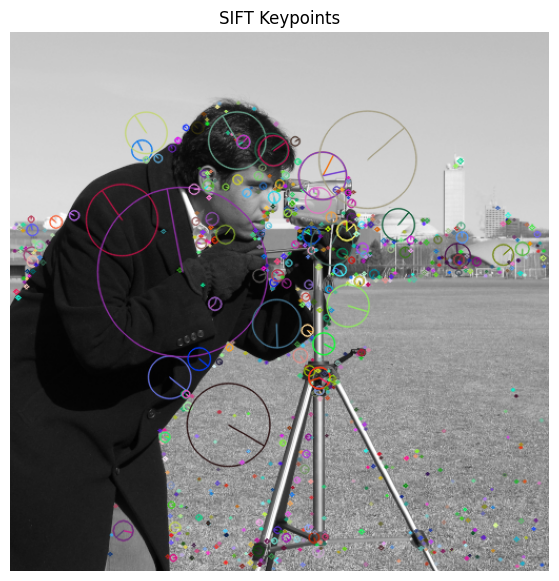

In [ ]:
import cv2
import matplotlib.pyplot as plt
from skimage import data

# Load grayscale image
image = data.camera().astype("uint8")

# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and compute descriptors
keypoints, descriptors = sift.detectAndCompute(
    image, None
)

# Draw keypoints
output = cv2.drawKeypoints(
    image,
    keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Print information
print("Number of keypoints:", len(keypoints))

if descriptors is not None:
    print("Descriptor shape:", descriptors.shape)
    print("Descriptor length:",
          descriptors.shape[1])

# Display
plt.figure(figsize=(10, 7))
plt.imshow(output, cmap="gray")
plt.title("SIFT Keypoints")
plt.axis("off")
plt.show()


Keypoints in image 1: 791
Keypoints in image 2: 872
Good matches: 477


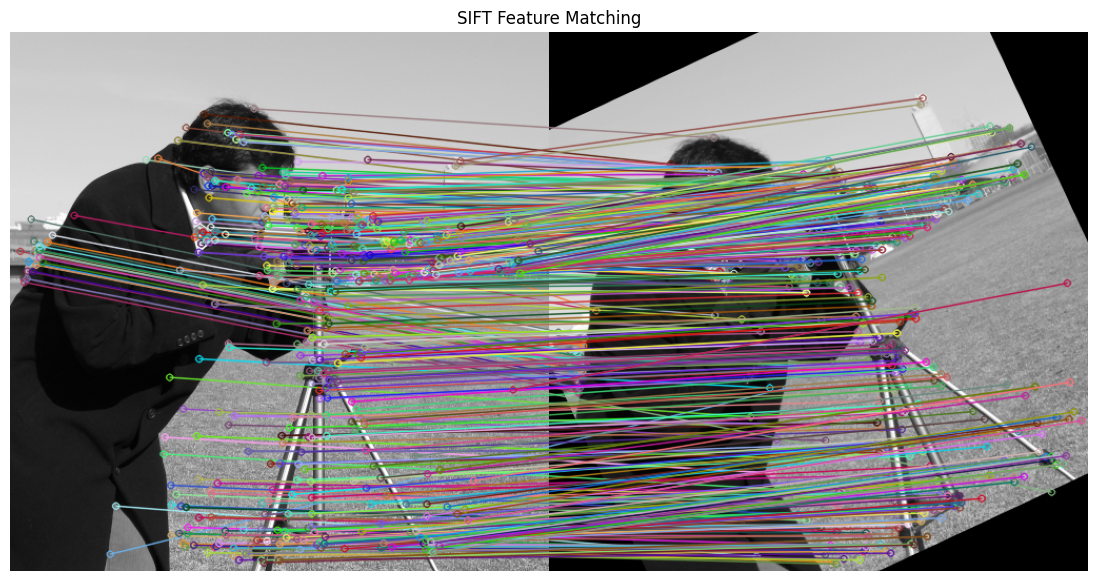

In [ ]:
import cv2
import matplotlib.pyplot as plt
from skimage import data

img1 = data.camera().astype("uint8")

# Create a rotated second image
h, w = img1.shape
center = (w // 2, h // 2)
M = cv2.getRotationMatrix2D(center, 25, 1.0)
img2 = cv2.warpAffine(img1, M, (w, h))

# SIFT
sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

# Brute-Force matcher using L2 distance
bf = cv2.BFMatcher(cv2.NORM_L2)

matches = bf.knnMatch(des1, des2, k=2)

# Lowe ratio test
good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

# Draw matches
result = cv2.drawMatches(
    img1, kp1, img2, kp2, good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

print("Keypoints in image 1:", len(kp1))
print("Keypoints in image 2:", len(kp2))
print("Good matches:", len(good_matches))

plt.figure(figsize=(14, 7))
plt.imshow(result, cmap="gray")
plt.title("SIFT Feature Matching")
plt.axis("off")
plt.show()

--- Comparison for 30-degree rotation ---
Keypoints in original image: 791
Keypoints in 30° rotated image: 894
Good matches: 475


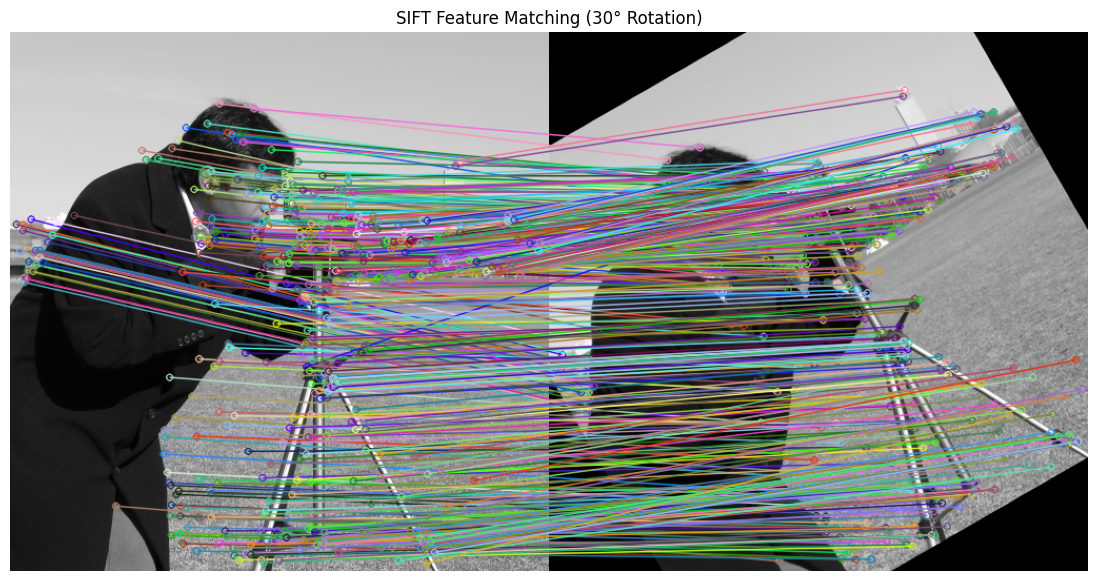

In [ ]:
import cv2
import matplotlib.pyplot as plt
from skimage import data

img1 = data.camera().astype("uint8")

# Create a rotated second image by 30 degrees
h, w = img1.shape
center = (w // 2, h // 2)
M_30 = cv2.getRotationMatrix2D(center, 30, 1.0)
img2_30 = cv2.warpAffine(img1, M_30, (w, h))

# Initialize SIFT detector
sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2_30, None)

# Brute-Force matcher with L2 distance
bf = cv2.BFMatcher(cv2.NORM_L2)
matches = bf.knnMatch(des1, des2, k=2)

# Apply Lowe's ratio test
good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

# Draw feature matches
result_30 = cv2.drawMatches(
    img1, kp1, img2_30, kp2, good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display statistics
print("--- Comparison for 30-degree rotation ---")
print("Keypoints in original image:", len(kp1))
print("Keypoints in 30° rotated image:", len(kp2))
print("Good matches:", len(good_matches))

# Plot the results
plt.figure(figsize=(14, 7))
plt.imshow(result_30, cmap="gray")
plt.title("SIFT Feature Matching (30° Rotation)")
plt.axis("off")
plt.show()

--- Comparison for 0.5x Scaling ---
Keypoints in original image: 791
Keypoints in scaled-down image: 241
Good matches found: 204


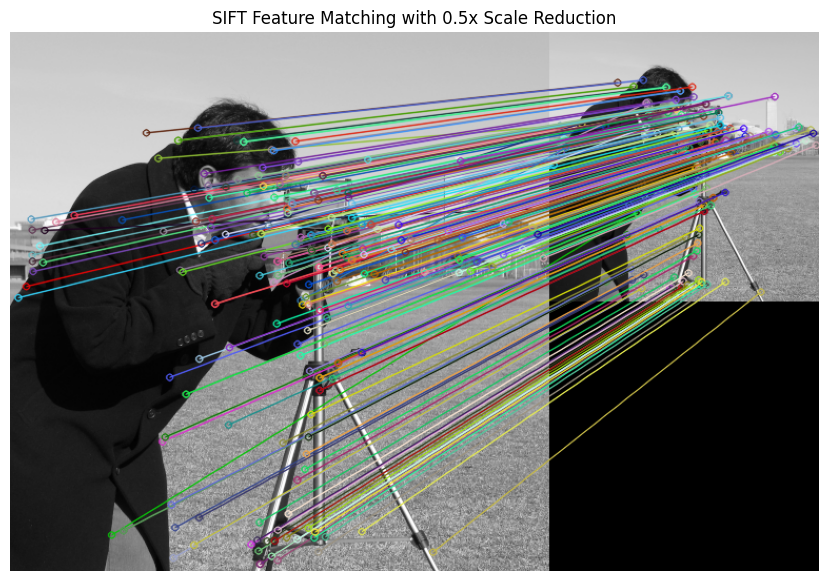

In [ ]:
import cv2
import matplotlib.pyplot as plt
from skimage import data

# Load original image
img1 = data.camera().astype("uint8")

# Scale the image down (0.5x scale)
scale_percent = 0.5
width = int(img1.shape[1] * scale_percent)
height = int(img1.shape[0] * scale_percent)
dim = (width, height)
img2_scaled = cv2.resize(img1, dim, interpolation=cv2.INTER_AREA)

# SIFT
sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2_scaled, None)

# Brute-Force matcher
bf = cv2.BFMatcher(cv2.NORM_L2)
matches = bf.knnMatch(des1, des2, k=2)

# Apply Lowe's ratio test
good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

# Draw matches
result_scale = cv2.drawMatches(
    img1, kp1, img2_scaled, kp2, good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

print("--- Comparison for 0.5x Scaling ---")
print("Keypoints in original image:", len(kp1))
print("Keypoints in scaled-down image:", len(kp2))
print("Good matches found:", len(good_matches))

plt.figure(figsize=(14, 7))
plt.imshow(result_scale, cmap="gray")
plt.title("SIFT Feature Matching with 0.5x Scale Reduction")
plt.axis("off")
plt.show()

### Evaluating SIFT Scale Invariance
We will resize the original image to 50% scale, detect keypoints using SIFT, and match them back to the original full-sized image using a Brute-Force matcher with Lowe's ratio test.

In [6]:
assert len(kp1) == des1.shape[0], f"Mismatch: {len(kp1)} keypoints but {des1.shape[0]} descriptors."
assert des1.shape[1] == 128, f"Descriptor dimension is {des1.shape[1]} instead of 128."

print("Verification Successful!")
print(f"✓ Total keypoints in original image: {len(kp1)}")
print(f"✓ Total descriptors in original image: {des1.shape[0]}")
print(f"✓ Dimension of each descriptor: {des1.shape[1]}")

Verification Successful!
✓ Total keypoints in original image: 791
✓ Total descriptors in original image: 791
✓ Dimension of each descriptor: 128


Keypoints in Original Image: 791
Keypoints in Rotated Image: 909
Recorded Number of Good Matches: 487


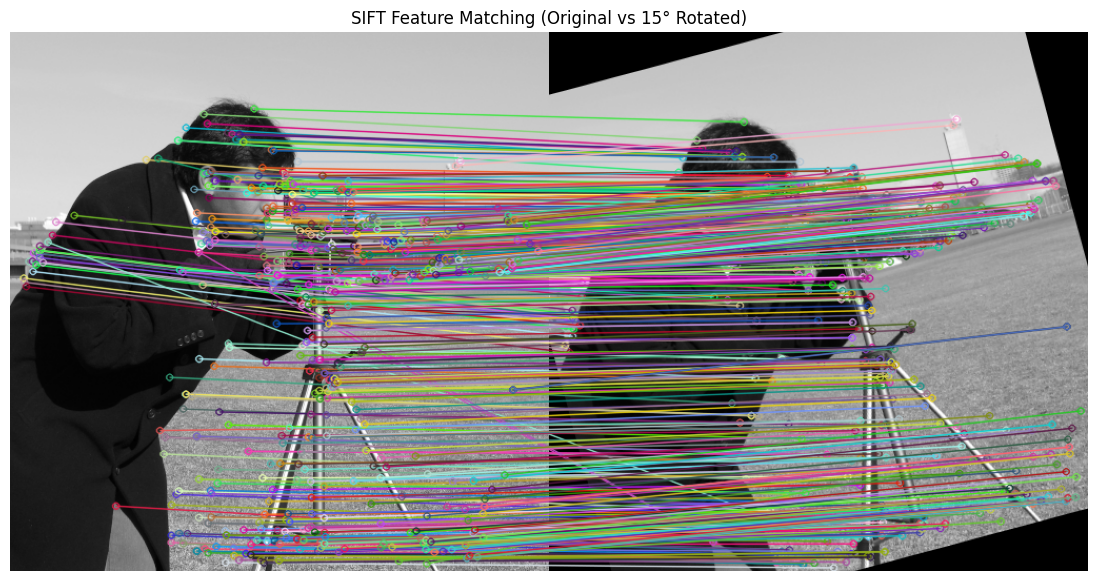

In [7]:
import cv2
import matplotlib.pyplot as plt
from skimage import data

# 1. Load two related images
image_orig = data.camera().astype("uint8")

# Create a related image (rotated by 15 degrees)
h, w = image_orig.shape
center = (w // 2, h // 2)
M_rotation = cv2.getRotationMatrix2D(center, 15, 1.0)
image_rotated = cv2.warpAffine(image_orig, M_rotation, (w, h))

# 2. Initialize SIFT detector and compute keypoints and descriptors
sift = cv2.SIFT_create()
kp_orig, des_orig = sift.detectAndCompute(image_orig, None)
kp_rot, des_rot = sift.detectAndCompute(image_rotated, None)

# 3. Match features using Brute-Force Matcher with L2 norm
bf = cv2.BFMatcher(cv2.NORM_L2)
knn_matches = bf.knnMatch(des_orig, des_rot, k=2)

# 4. Filter matches using Lowe's ratio test (ratio threshold = 0.75)
good_matches = []
for m, n in knn_matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

# 5. Record and print the number of good matches
num_good_matches = len(good_matches)
print(f"Keypoints in Original Image: {len(kp_orig)}")
print(f"Keypoints in Rotated Image: {len(kp_rot)}")
print(f"Recorded Number of Good Matches: {num_good_matches}")

# 6. Draw and display the matches
matching_result = cv2.drawMatches(
    image_orig, kp_orig, image_rotated, kp_rot, good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(14, 7))
plt.imshow(matching_result, cmap="gray")
plt.title("SIFT Feature Matching (Original vs 15° Rotated)")
plt.axis("off")
plt.show()

Why SIFT is More Useful Than Raw Pixel Comparison
Directly comparing raw pixel values (such as using SSD or NCC patch matching) is rarely effective in computer vision. SIFT (Scale-Invariant Feature Transform) is vastly superior due to the following key properties:

1. Geometric Invariances
Scale Invariance: Raw pixel matching fails if an object changes distance from the camera. SIFT detects keypoints across a multi-scale pyramid (using Difference-of-Gaussians), making it highly robust to zooming.
Rotation Invariance: If an image is rotated, raw pixel neighborhoods change completely. SIFT calculates a dominant gradient orientation for each keypoint and rotates the descriptor vector relative to this angle, allowing reliable matching at any angle.
2. Photometric Invariance
Illumination Robustness: Raw pixel values shift dramatically under different lighting conditions. SIFT descriptors represent the relative gradients (changes in intensity) rather than absolute pixel values, and the final 128-D vector is normalized to reduce the effects of illumination shifts and contrast adjustments.
3. Viewpoint/Affine Invariance
Perspective Changes: SIFT is highly robust to minor shifts in 3D camera viewpoints, whereas a direct pixel-by-pixel alignment degrades rapidly with even a tiny perspective skew.
4. High Distinctiveness (Sparsity & Contrast)
Distinctiveness: SIFT focuses on unique local structures (like corners and complex textures) and maps them into a 128-dimensional space. This allows unique matching even within highly cluttered scenes, whereas raw pixel patches can easily be confused with other similar-looking uniform regions.